BÀI TẬP VỀ NHÀ

Bài 1. Thay đổi điều kiện sinh dữ liệu, ví dụ tăng độ nhiễu để kiểm tra độ chính xác của mô
hình


===== MỨC NHIỄU: 0.1 =====
Hệ số chặn: 4.014291331945855
Hệ số góc: 2.9799323657480286
MSE: 0.006536995137170057
RMSE: 0.08085168605026154
R²: 0.9981214706962858

===== MỨC NHIỄU: 1 =====
Hệ số chặn: 3.8856885985243546
Hệ số góc: 2.9841063498096285
MSE: 2.0715220099265226
RMSE: 1.4392782948153295
R²: 0.5884398969708723

===== MỨC NHIỄU: 5 =====
Hệ số chặn: 4.441627677237072
Hệ số góc: 3.1610110079696563
MSE: 8.91822854996474
RMSE: 2.9863403272173685
R²: 0.38067777686079973


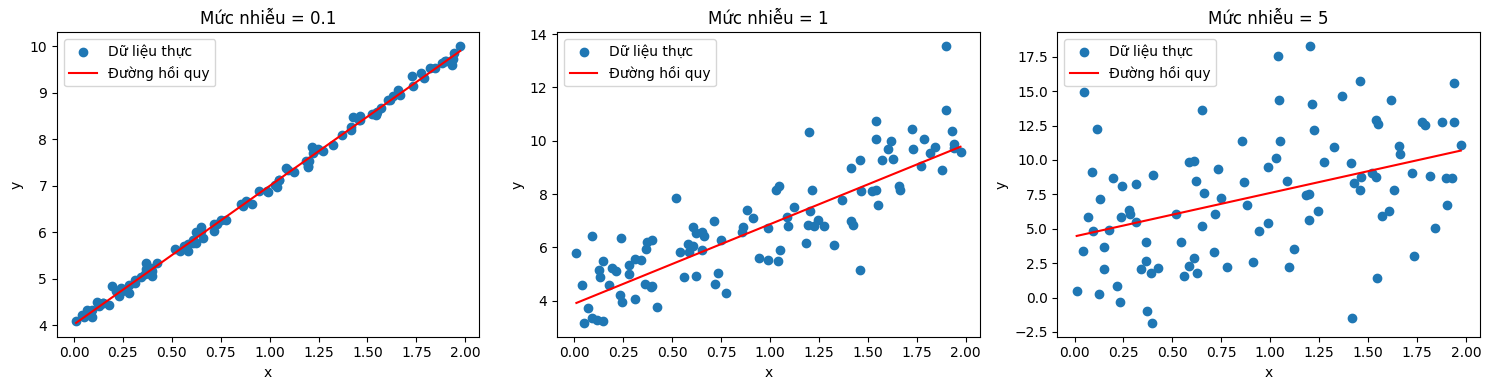

In [1]:
# import thư viện cần thiết
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# 1. Tạo dữ liệu đầu vào
np.random.seed(42)
x = 2 * np.random.rand(100, 1)

# Thử nghiệm với 3 mức nhiễu khác nhau
noise_levels = [0.1, 1, 5]
plt.figure(figsize=(15, 4))
for i, noise_level in enumerate(noise_levels):

    # 2. Tạo dữ liệu đầu ra với mức nhiễu tương ứng
    noise = np.random.randn(100, 1) * noise_level
    y = 4 + 3 * x + noise

    # 3. Chia dữ liệu thành tập huấn luyện và kiểm tra
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

    # 4. Khởi tạo mô hình
    model = LinearRegression()

    # 5. Huấn luyện mô hình
    model.fit(x_train, y_train)

    # 6. Dự đoán
    y_pred = model.predict(x_test)

    # 7. Đánh giá mô hình
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # 8. In kết quả
    print(f"\n===== MỨC NHIỄU: {noise_level} =====")
    print("Hệ số chặn:", model.intercept_[0])
    print("Hệ số góc:", model.coef_[0][0])
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R²:", r2)

    # 9. Vẽ dữ liệu và đường hồi quy
    plt.subplot(1, 3, i + 1)
    plt.scatter(x, y, label="Dữ liệu thực")
    x_line = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)
    y_line = model.predict(x_line)
    plt.plot(x_line, y_line, color="red", label="Đường hồi quy")
    plt.title(f"Mức nhiễu = {noise_level}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend()

plt.tight_layout()
plt.show()

Bài 2. Đổi ngưỡng dự đoán xác suất (ví dụ 0.6, 0.7,… thay vì 0.5) và quan sát sự thay đổi
trong kết quả dự đoán.

Hệ số mô hình: 0.34078301291753754
Hệ số chặn: -9.205336895524036

===== NGƯỠNG = 0.5 =====
Accuracy: 0.8333333333333334
Confusion Matrix:
[[21  7]
 [ 3 29]]
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.75      0.81        28
           1       0.81      0.91      0.85        32

    accuracy                           0.83        60
   macro avg       0.84      0.83      0.83        60
weighted avg       0.84      0.83      0.83        60


===== NGƯỠNG = 0.6 =====
Accuracy: 0.85
Confusion Matrix:
[[22  6]
 [ 3 29]]
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.79      0.83        28
           1       0.83      0.91      0.87        32

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60


===== NGƯỠNG = 0.7 =====
Accuracy: 0.85
Confusion Matrix:
[[24 

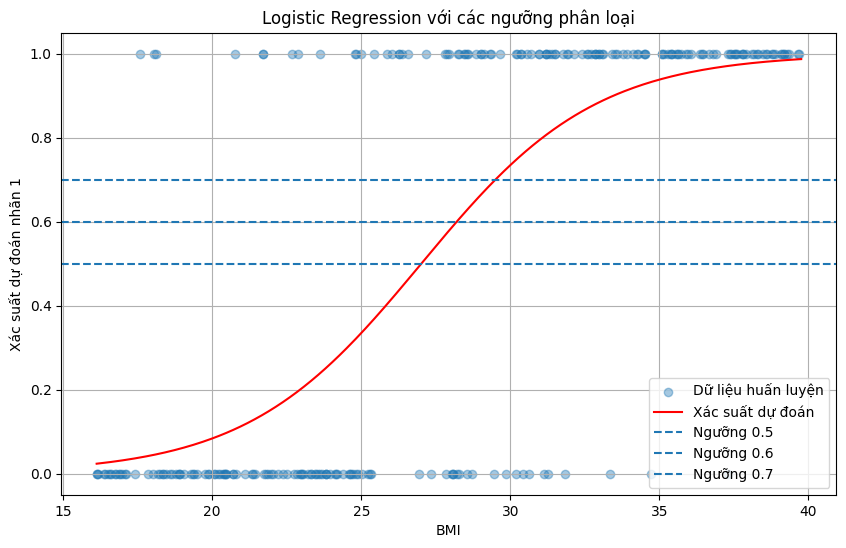

In [2]:
# import thư viên cần thiết
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

# 1. Tạo dữ liệu BMI giả lập
np.random.seed(42)
n_samples = 300
BMI = np.random.uniform(16, 40, n_samples)

# Tạo xác suất giả lập: BMI càng cao thì xác suất nhãn 1
# có xu hướng tăng. Đây là dữ liệu nhân tạo để học thuật toán.
true_probability = 1 / (1 + np.exp(-(BMI - 27) / 3))

# Sinh nhãn 0/1 theo xác suất giả lập
y = (np.random.rand(n_samples) < true_probability).astype(int)

# Chuyển BMI thành ma trận có một cột
X = BMI.reshape(-1, 1)

# 2. Chia dữ liệu thành tập huấn luyện và kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Tạo và huấn luyện mô hình
model = LogisticRegression()
model.fit(X_train, y_train)

# 4. Tính xác suất thuộc lớp 1 trên tập kiểm tra
probabilities = model.predict_proba(X_test)[:, 1]
print("Hệ số mô hình:", model.coef_[0][0])
print("Hệ số chặn:", model.intercept_[0])

# 5. Thử nhiều ngưỡng
thresholds = [0.5, 0.6, 0.7]
for threshold in thresholds:

    # Xác suất >= ngưỡng thì dự đoán 1, ngược lại dự đoán 0
    y_pred = (probabilities >= threshold).astype(int)
    accuracy = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    print(f"\n===== NGƯỠNG = {threshold} =====")
    print("Accuracy:", accuracy)
    print("Confusion Matrix:")
    print(cm)

    print("Classification Report:")
    print(classification_report(y_test, y_pred, labels=[0, 1], zero_division=0))

# 6. Vẽ dữ liệu BMI và xác suất dự đoán
bmi_range = np.linspace(BMI.min(), BMI.max(), 300).reshape(-1, 1)
probability_curve = model.predict_proba(bmi_range)[:, 1]
plt.figure(figsize=(10, 6))
plt.scatter(X_train[:, 0], y_train,alpha=0.4, label="Dữ liệu huấn luyện")
plt.plot(bmi_range[:, 0], probability_curve,color="red", label="Xác suất dự đoán")
plt.axhline(0.5, linestyle="--", label="Ngưỡng 0.5")
plt.axhline(0.6, linestyle="--", label="Ngưỡng 0.6")
plt.axhline(0.7, linestyle="--", label="Ngưỡng 0.7")
plt.xlabel("BMI")
plt.ylabel("Xác suất dự đoán nhãn 1")
plt.title("Logistic Regression với các ngưỡng phân loại")
plt.legend()
plt.grid(True)
plt.show()

Bài 3. Hồi quy tuyến tính với tập dữ liệu giá nhà ở

Mô tả: Sử dụng thuật toán Linear Regression để dự đoán giá nhà dựa trên một số thuộc tính.
Yêu cầu:7
- Tải tập dữ liệu Boston Housing từ sklearn.datasets (có thể tải từ kaggle).
- Phân chia dữ liệu thành tập huấn luyện và tập kiểm tra.
- Huấn luyện mô hình hồi quy tuyến tính trên tập huấn luyện và dự đoán trên tập kiểm
tra.
- Tính toán các chỉ số đánh giá: MSE (Mean Squared Error) và R² score cho tập kiểm tra.

5 dòng dữ liệu đầu tiên:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Kích thước bộ dữ liệu:
(20640, 9)

Thông tin các cột:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     2

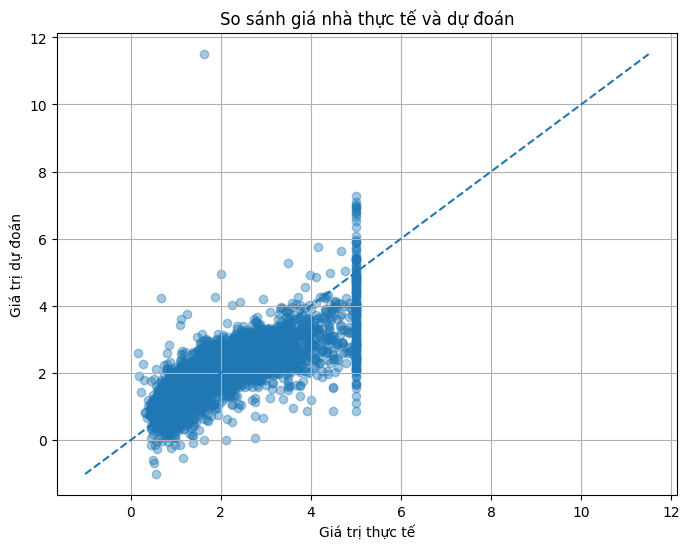

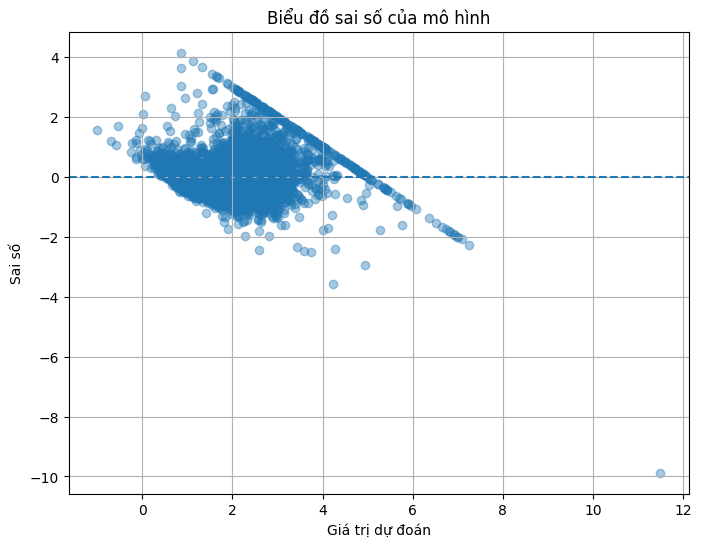

In [3]:
# Bước 1: import thư viện cần thiết
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Bước 2: Tải bộ dữ liệu
housing = fetch_california_housing(as_frame=True)

# Chuyển dữ liệu thành DataFrame
df = housing.frame

print("5 dòng dữ liệu đầu tiên:")
print(df.head())

print("\nKích thước bộ dữ liệu:")
print(df.shape)

print("\nThông tin các cột:")
print(df.info())

print("\nThống kê mô tả:")
print(df.describe())


# Bước 3: Kiểm tra dữ liệu thiếu
print("\nSố lượng giá trị thiếu ở từng cột:")
print(df.isnull().sum())

# Bước 4: Chọn Biến đầu vào và Biến đầu ra
# Các biến đầu vào
X = df.drop(columns=["MedHouseVal"])

# Biến mục tiêu: giá trị nhà trung vị
y = df["MedHouseVal"]

print("\nCác biến đầu vào:")
print(X.columns.tolist())

print("\nBiến đầu ra:")
print(y.name)

# Bước 5: Chia dữ liệu
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print("\nSố mẫu huấn luyện:", len(X_train))
print("Số mẫu kiểm tra:", len(X_test))

# Bước 6: Khởi tạo mô hình
model = LinearRegression()

# Bước 7: Huấn luyện mô hình
model.fit(X_train, y_train)

# Bước 8: Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

# Bước 9: Đánh giá mô hình
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n========== KẾT QUẢ ĐÁNH GIÁ ==========")
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

# Bước 10: In hệ số hồi quy
print("\n========== HỆ SỐ MÔ HÌNH ==========")
print("Hệ số chặn (Intercept):", model.intercept_)
coefficients = pd.DataFrame({"Đặc trưng": X.columns, "Hệ số hồi quy": model.coef_})
print(coefficients)

# Bước 11: So sánh giá trị thực tế và dự đoán
comparison = pd.DataFrame({"Giá trị thực tế": y_test.to_numpy(), "Giá trị dự đoán": y_pred})
comparison["Sai số"] = (comparison["Giá trị thực tế"] - comparison["Giá trị dự đoán"])

print("\n10 kết quả dự đoán đầu tiên:")
print(comparison.head(10))

# Bươc 12: Vẽ biểu đồ so sánh
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.4)
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value],linestyle="--")

plt.xlabel("Giá trị thực tế")
plt.ylabel("Giá trị dự đoán")
plt.title("So sánh giá nhà thực tế và dự đoán")

plt.grid(True)
plt.show()

# Bước 13: Vẽ biểu đồ sai số
residuals = y_test.to_numpy() - y_pred
plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Giá trị dự đoán")
plt.ylabel("Sai số")
plt.title("Biểu đồ sai số của mô hình")

plt.grid(True)
plt.show()